# ML Assignment 1 – Uber Fare Prediction
**Problem Statement:** Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and random forest regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE, etc.

Dataset: `uber.csv` (kept in the same folder).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

## 1. Pre-process the dataset

In [2]:
df = pd.read_csv('uber.csv')
print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [4]:
# Drop useless columns (index column and key)
df = df.drop(columns=['Unnamed: 0', 'key'])
print(df.isnull().sum())

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [5]:
# Remove rows with missing values
df = df.dropna()

# Convert pickup_datetime to datetime and extract useful features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], errors='coerce')
df = df.dropna(subset=['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.day
df['month'] = df['pickup_datetime'].dt.month
df['year'] = df['pickup_datetime'].dt.year
df['dayofweek'] = df['pickup_datetime'].dt.dayofweek
df = df.drop(columns=['pickup_datetime'])
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [6]:
# Distance between pickup and drop-off using the Haversine formula (in km)
def haversine(lon1, lat1, lon2, lat2):
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon, dlat = lon2 - lon1, lat2 - lat1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df['distance_km'] = haversine(df['pickup_longitude'], df['pickup_latitude'],
                              df['dropoff_longitude'], df['dropoff_latitude'])
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fare_amount,199999.0,11.359892,9.901760,-52.000000,6.000000,8.500000,12.500000,499.000000
pickup_longitude,199999.0,-72.527631,11.437815,-1340.648410,-73.992065,-73.981823,-73.967154,57.418457
pickup_latitude,199999.0,39.935881,7.720558,-74.015515,40.734796,40.752592,40.767158,1644.421482
dropoff_longitude,199999.0,-72.525292,13.117408,-3356.666300,-73.991407,-73.980093,-73.963658,1153.572603
dropoff_latitude,199999.0,39.923890,6.794829,-881.985513,40.733823,40.753042,40.768001,872.697628
passenger_count,199999.0,1.684543,1.385995,0.000000,1.000000,1.000000,2.000000,208.000000
hour,199999.0,13.491387,6.515505,0.000000,9.000000,14.000000,19.000000,23.000000
day,199999.0,15.704739,8.687377,1.000000,8.000000,16.000000,23.000000,31.000000
month,199999.0,6.281791,3.438933,1.000000,3.000000,6.000000,9.000000,12.000000
year,199999.0,2011.742434,1.856400,2009.000000,2010.000000,2012.000000,2013.000000,2015.000000


## 2. Identify outliers

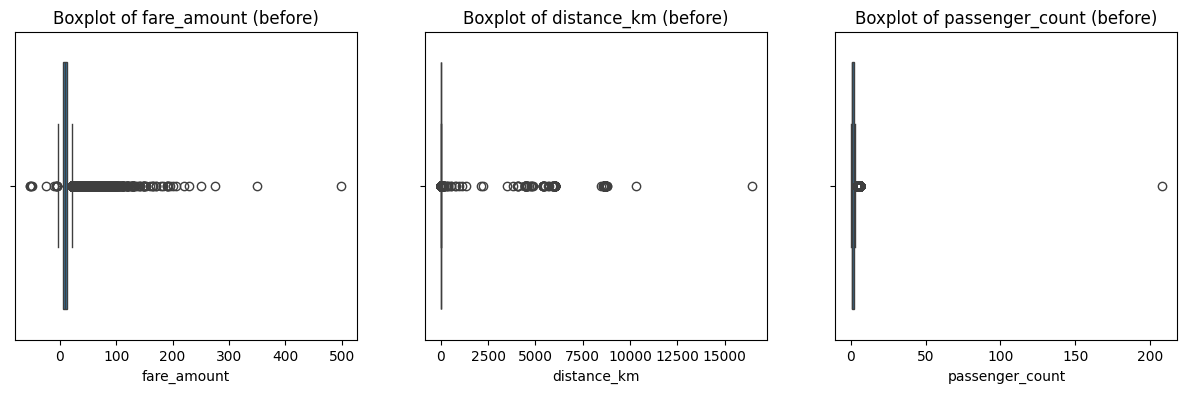

In [7]:
cols = ['fare_amount', 'distance_km', 'passenger_count']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Boxplot of {col} (before)')
plt.show()

Shape after removing outliers: (168900, 12)


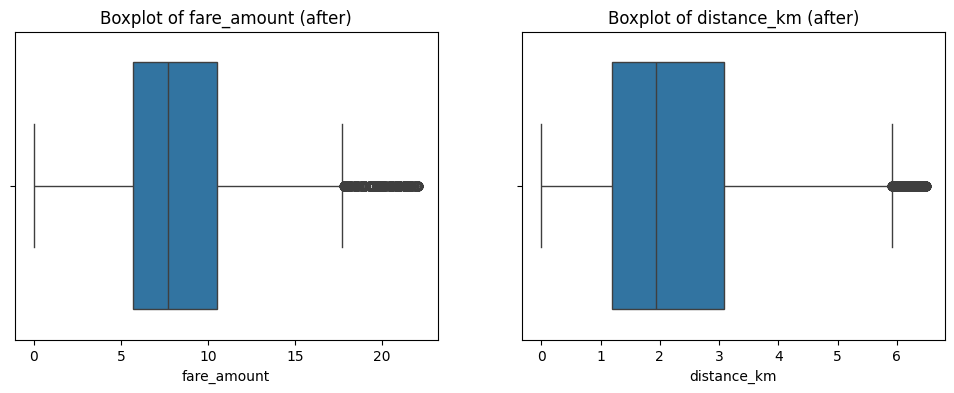

In [8]:
# Remove impossible values (domain knowledge)
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 200)]
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]
df = df[df['pickup_latitude'].between(-90, 90) & df['dropoff_latitude'].between(-90, 90)]
df = df[df['pickup_longitude'].between(-180, 180) & df['dropoff_longitude'].between(-180, 180)]
df = df[(df['distance_km'] > 0) & (df['distance_km'] < 100)]

# Remove remaining outliers using the IQR method
def remove_outliers_iqr(data, col):
    q1, q3 = data[col].quantile(0.25), data[col].quantile(0.75)
    iqr = q3 - q1
    return data[(data[col] >= q1 - 1.5 * iqr) & (data[col] <= q3 + 1.5 * iqr)]

for col in ['fare_amount', 'distance_km']:
    df = remove_outliers_iqr(df, col)

print('Shape after removing outliers:', df.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['fare_amount', 'distance_km']):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Boxplot of {col} (after)')
plt.show()

## 3. Check the correlation

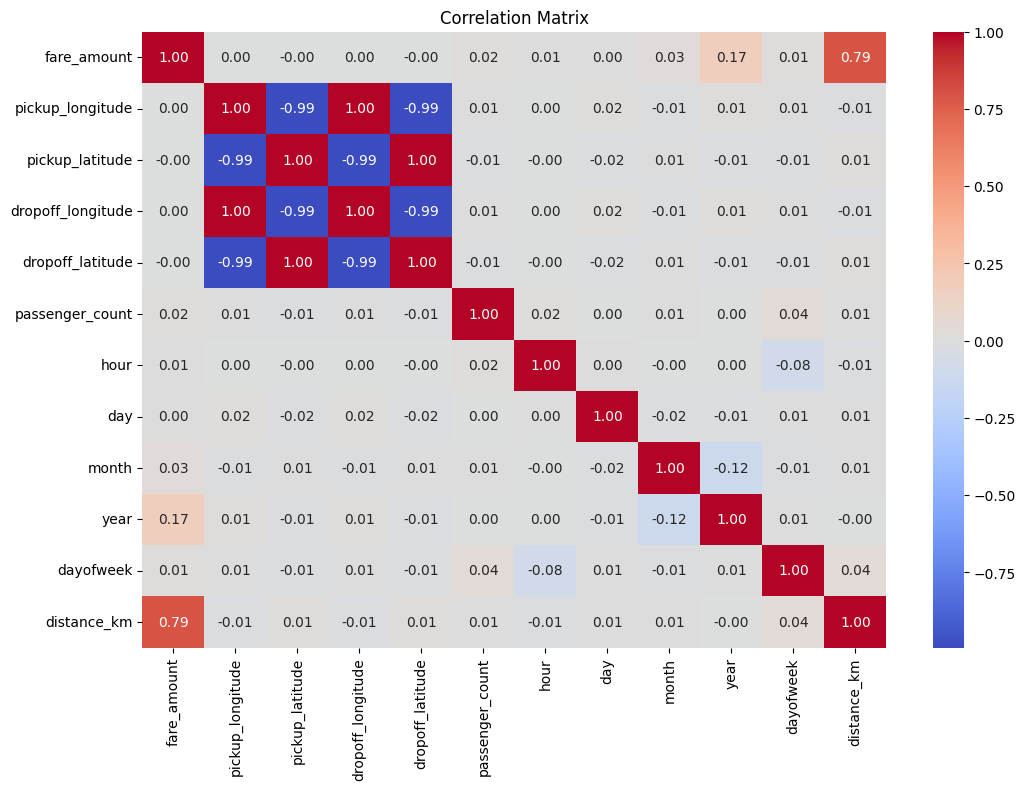

fare_amount          1.000000
distance_km          0.794940
year                 0.173399
month                0.032664
passenger_count      0.016927
dayofweek            0.012989
hour                 0.006800
day                  0.004899
dropoff_longitude    0.002949
pickup_longitude     0.002519
pickup_latitude     -0.003352
dropoff_latitude    -0.003711
Name: fare_amount, dtype: float64


In [9]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()
print(df.corr()['fare_amount'].sort_values(ascending=False))

## 4. Implement Linear Regression and Random Forest Regression

In [10]:
X = df.drop(columns=['fare_amount'])
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(135120, 11) (33780, 11)


In [11]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

In [12]:
# n_estimators kept small so it trains quickly on lab PCs
rf = RandomForestRegressor(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

## 5. Evaluate and compare models

In [13]:
def evaluate(name, y_true, y_pred):
    return {'Model': name,
            'R2': r2_score(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'MAE': mean_absolute_error(y_true, y_pred)}

results = pd.DataFrame([evaluate('Linear Regression', y_test, y_pred_lr),
                        evaluate('Random Forest', y_test, y_pred_rf)])
results

,Model,R2,RMSE,MAE
0,Linear Regression,0.667500,2.142622,1.528151
1,Random Forest,0.736902,1.905936,1.319613


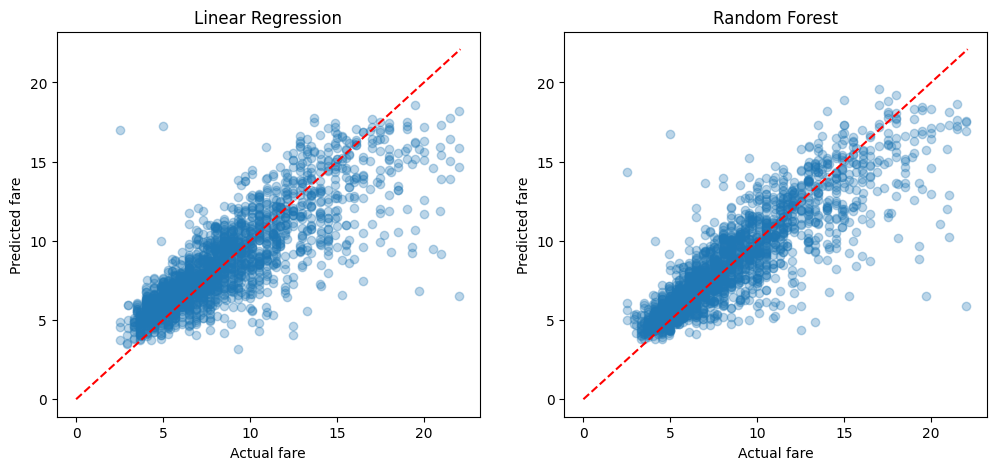

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, name in zip(axes, [y_pred_lr, y_pred_rf], ['Linear Regression', 'Random Forest']):
    ax.scatter(y_test[:2000], pred[:2000], alpha=0.3)
    ax.plot([0, y_test.max()], [0, y_test.max()], 'r--')
    ax.set_xlabel('Actual fare'); ax.set_ylabel('Predicted fare'); ax.set_title(name)
plt.show()

**Conclusion:** Random Forest gives a higher R2 and lower RMSE than Linear Regression, because it captures the non-linear relationship between distance/time features and fare. Distance is the feature most correlated with fare.